In [11]:
import tensorflow as tf
import matplotlib.pyplot as plt

#import pandas as pd
#mport seaborn as sns

In [12]:
import os
print('Current Working Directory:', os.getcwd())

Current Working Directory: c:\Users\kanis\OneDrive\Documents\AICW\Plant_leaf_disaster_predicator


In [13]:
#import os
#print('Current Working Directory:', os.getcwd())
current_directory = os.getcwd()
train_path = os.path.join(current_directory, 'data','PLD_3_Classes_256', 'Training')
valid_path = os.path.join(current_directory, 'data','PLD_3_Classes_256', 'Validation')
test_path = os.path.join(current_directory, 'data','PLD_3_Classes_256', 'Testing')

In [14]:
train_path

'c:\\Users\\kanis\\OneDrive\\Documents\\AICW\\Plant_leaf_disaster_predicator\\data\\PLD_3_Classes_256\\Training'

In [15]:
valid_path

'c:\\Users\\kanis\\OneDrive\\Documents\\AICW\\Plant_leaf_disaster_predicator\\data\\PLD_3_Classes_256\\Validation'

In [16]:
test_path

'c:\\Users\\kanis\\OneDrive\\Documents\\AICW\\Plant_leaf_disaster_predicator\\data\\PLD_3_Classes_256\\Testing'

In [17]:
#function that  is used to create an image dataset from a directory of images. It takes in the path to the directory, the batch size, and the image size as arguments. It returns a tf.data.Dataset object that can be used to train a model.   
training_set=tf.keras.utils.image_dataset_from_directory(
    train_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128,128),
    shuffle=True,
    interpolation="bilinear"
)

Found 3251 files belonging to 3 classes.


In [18]:
validation_set=tf.keras.utils.image_dataset_from_directory(
    valid_path,
    labels="inferred",
    label_mode="categorical",
    class_names=None,
    color_mode="rgb",
    batch_size=32,
    image_size=(128,128),
    shuffle=True,
    interpolation="bilinear"
)

Found 416 files belonging to 3 classes.


In [19]:
cnn = tf.keras.models.Sequential()

cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,padding='same',activation='relu',input_shape=[128,128,3]))
cnn.add(tf.keras.layers.Conv2D(filters=32,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=64,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=128,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=256,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,padding='same',activation='relu'))
cnn.add(tf.keras.layers.Conv2D(filters=512,kernel_size=3,activation='relu'))
cnn.add(tf.keras.layers.MaxPool2D(pool_size=2,strides=2))

cnn.add(tf.keras.layers.Dropout(0.25))

cnn.add(tf.keras.layers.Flatten())
cnn.add(tf.keras.layers.Dense(units=1500,activation='relu'))
cnn.add(tf.keras.layers.Dropout(0.4))

cnn.add(tf.keras.layers.Dense(units=3,activation='softmax'))

c:\Users\kanis\OneDrive\Documents\AICW\Plant_leaf_disaster_predicator\.venv\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [20]:
cnn.compile(optimizer=tf.keras.optimizers.Adam(
    learning_rate=0.0001
), loss='categorical_crossentropy', metrics=['accuracy'])

In [21]:
cnn.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 126, 126, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 63, 63, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 61, 61, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 30, 30, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 28, 28, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 14, 14, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 12, 12, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 6, 6, 512)      │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 4, 4, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2, 2, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1500)           │     3,073,500 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1500)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │         4,503 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 7,790,227 (29.72 MB)

 Trainable params: 7,790,227 (29.72 MB)

 Non-trainable params: 0 (0.00 B)

In [22]:
training_history = cnn.fit(x=training_set, validation_data=validation_set, epochs=10)

Epoch 1/10


c:\Users\kanis\OneDrive\Documents\AICW\Plant_leaf_disaster_predicator\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


102/102 ━━━━━━━━━━━━━━━━━━━━ 54s 508ms/step - accuracy: 0.5174 - loss: 1.0586 - val_accuracy: 0.5433 - val_loss: 0.9219
Epoch 2/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 51s 498ms/step - accuracy: 0.6263 - loss: 0.8402 - val_accuracy: 0.5986 - val_loss: 0.8599
Epoch 3/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 51s 498ms/step - accuracy: 0.7530 - loss: 0.6175 - val_accuracy: 0.7668 - val_loss: 0.5950
Epoch 4/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 50s 489ms/step - accuracy: 0.8262 - loss: 0.4674 - val_accuracy: 0.8726 - val_loss: 0.3378
Epoch 5/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 53s 521ms/step - accuracy: 0.8834 - loss: 0.3267 - val_accuracy: 0.8966 - val_loss: 0.2868
Epoch 6/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 68s 668ms/step - accuracy: 0.9102 - loss: 0.2558 - val_accuracy: 0.9062 - val_loss: 0.2784
Epoch 7/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 74s 725ms/step - accuracy: 0.9194 - loss: 0.2204 - val_accuracy: 0.9255 - val_loss: 0.2145
Epoch 8/10
102/102 ━━━━━━━━━━━━━━━━━━━━ 60s 593ms/step - accuracy: 0.9379 - loss: 0.1759 - val

In [24]:
val_loss,val_acc = cnn.evaluate(validation_set)
print('Validation accuracy:', val_acc)

13/13 ━━━━━━━━━━━━━━━━━━━━ 2s 145ms/step - accuracy: 0.9183 - loss: 0.2886
Validation accuracy: 0.9182692170143127


In [25]:
cnn.save('trained_plant_disease_model.h5')

In [26]:
training_history.history

{'accuracy': [0.5173792839050293,
  0.6262688636779785,
  0.7529990673065186,
  0.8262073397636414,
  0.883420467376709,
  0.91018146276474,
  0.9194093942642212,
  0.9378652572631836,
  0.9387880563735962,
  0.9572439193725586],
 'loss': [1.0585932731628418,
  0.8401872515678406,
  0.6175209879875183,
  0.46740442514419556,
  0.32673805952072144,
  0.255812406539917,
  0.2203555405139923,
  0.1759369671344757,
  0.16516081988811493,
  0.11915963143110275],
 'val_accuracy': [0.5432692170143127,
  0.598557710647583,
  0.7668269276618958,
  0.8725961446762085,
  0.8966346383094788,
  0.90625,
  0.9254807829856873,
  0.9375,
  0.9254807829856873,
  0.9182692170143127],
 'val_loss': [0.921938955783844,
  0.8599295020103455,
  0.5949755311012268,
  0.33780038356781006,
  0.28677523136138916,
  0.27837103605270386,
  0.2145473212003708,
  0.19860433042049408,
  0.23735174536705017,
  0.2885816991329193]}

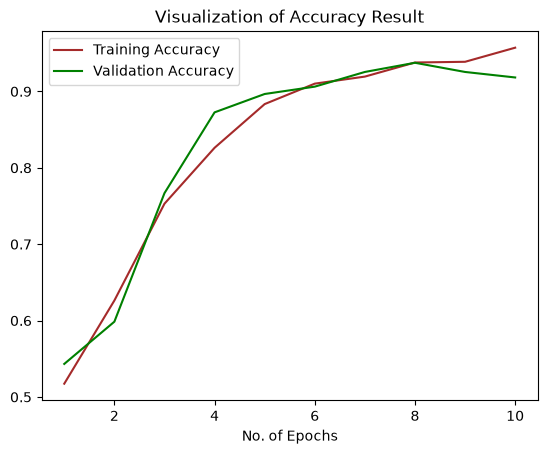

In [27]:
epochs = [i for i in range(1,11)]
plt.plot(epochs,training_history.history['accuracy'],color='brown',label='Training Accuracy')
plt.plot(epochs,training_history.history['val_accuracy'],color='green',label='Validation Accuracy')
plt.xlabel('No. of Epochs')
plt.title('Visualization of Accuracy Result')
plt.legend()
plt.show()